<a href="https://colab.research.google.com/github/rajeshdchikkala/Ai-Datascience/blob/main/Copy_of_VAE_ON_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, Model
from tensorflow.keras.datasets import mnist

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [ ]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)
print("Number of classes:", len(np.unique(y_train)))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training shape: (60000, 28, 28)
Testing shape: (10000, 28, 28)
Number of classes: 10


Preprocess the images
Neural networks work better with normalized input values.

MNIST pixel values range from 0 to 255. We normalize them to 0 to 1.

In [ ]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten images from 28x28 into 784 features
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (60000, 784)
Testing data: (10000, 784)


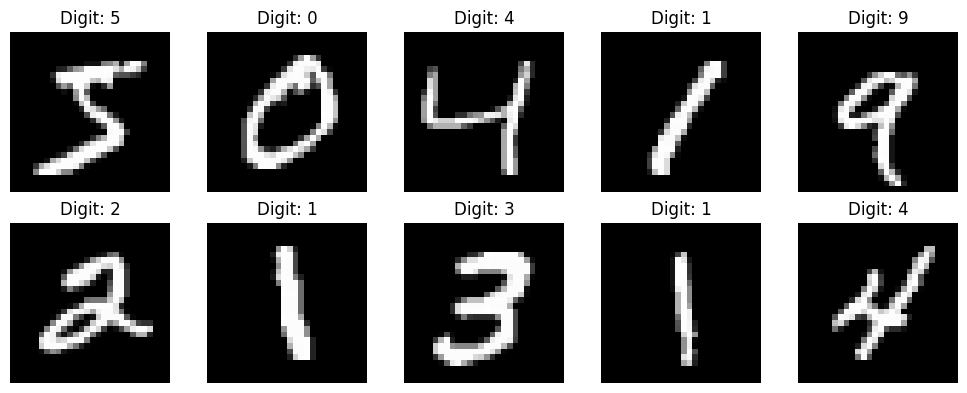

In [ ]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Build the VAE Encoder

 encoder will:
1. Receive 784 input features.
2. Pass through a hidden dense layer.
3. Produce two outputs: mean and log variance.
4. Use these values to define a probability distribution.
We use a latent dimension of
2 so that we can visualize the latent space later.

In [ ]:
latent_dim = 2

# Encoder input
encoder_inputs = layers.Input(shape=(784,))

# Hidden layer
x = layers.Dense(256, activation="relu")(encoder_inputs)

# Mean
z_mean = layers.Dense(latent_dim, name="z_mean")(x)

# Log variance
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)

encoder = Model(encoder_inputs, [z_mean, z_log_var], name="encoder")

encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 784)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    200,960 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        514 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        514 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 201,988 (789.02 KB)

 Trainable params: 201,988 (789.02 KB)

 Non-trainable params: 0 (0.00 B)

What is log variance?

Instead of directly predicting variance, we predict its logarithm.

This is useful because variance must be positive, whereas log variance can take any real value.

We recover standard deviation using:

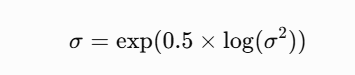

Step 6: Implement the Reparameterization Trick
This is the most important programming concept in VAE.

In [ ]:
class Sampling(layers.Layer):

    def call(self, inputs):

        z_mean, z_log_var = inputs

        epsilon = tf.random.normal( shape=tf.shape(z_mean) )

        z = z_mean + tf.exp(0.5 * z_log_var) * epsilon

        return z

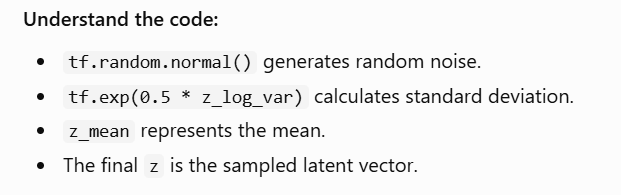

For example, suppose:
Mean = 0.5
Log variance = 0
Random noise = 0.8
Then


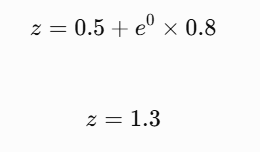

The model uses this sampled value instead of directly passing the mean to the decoder.

In [ ]:
latent_inputs = layers.Input(shape=(latent_dim,))

x = layers.Dense(256, activation="relu")(latent_inputs)

decoder_outputs = layers.Dense( 784, activation="sigmoid")(x)

decoder = Model(  latent_inputs, decoder_outputs, name="decoder")

decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 202,256 (790.06 KB)

 Trainable params: 202,256 (790.06 KB)

 Non-trainable params: 0 (0.00 B)

Connect Encoder, Sampling and Decoder

In [ ]:
class VAE(Model):

    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)

        self.encoder = encoder
        self.decoder = decoder
        self.sampling = Sampling()

        self.total_loss_tracker = tf.keras.metrics.Mean(
            name="loss"
        )

        self.reconstruction_loss_tracker = tf.keras.metrics.Mean(
            name="reconstruction_loss"
        )

        self.kl_loss_tracker = tf.keras.metrics.Mean(
            name="kl_loss"
        )

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker
        ]

    def train_step(self, data):

        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:

            z_mean, z_log_var = self.encoder(data)

            z = self.sampling([z_mean, z_log_var])

            reconstruction = self.decoder(z)

            # Reconstruction loss (Sum of binary crossentropy over pixels, then mean over batch)
            reconstruction_loss = tf.keras.losses.binary_crossentropy(
                data, reconstruction
            )
            # multiply by 784 to scale it from average to sum over pixels
            reconstruction_loss = tf.reduce_mean(reconstruction_loss) * 784

            # KL Divergence loss
            kl_loss = -0.5 * tf.reduce_sum(
                1 + z_log_var
                - tf.square(z_mean)
                - tf.exp(z_log_var),
                axis=1
            )

            kl_loss = tf.reduce_mean(kl_loss)

            # Total loss
            total_loss = reconstruction_loss + kl_loss

        gradients = tape.gradient(
            total_loss,
            self.trainable_weights
        )

        self.optimizer.apply_gradients(
            zip(gradients, self.trainable_weights)
        )

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(
            reconstruction_loss
        )
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss":
                self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result()
        }

    def test_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        z_mean, z_log_var = self.encoder(data)
        z = self.sampling([z_mean, z_log_var])
        reconstruction = self.decoder(z)

        reconstruction_loss = tf.keras.losses.binary_crossentropy(
            data, reconstruction
        )
        reconstruction_loss = tf.reduce_mean(reconstruction_loss) * 784

        kl_loss = -0.5 * tf.reduce_sum(
            1 + z_log_var
            - tf.square(z_mean)
            - tf.exp(z_log_var),
            axis=1
        )
        kl_loss = tf.reduce_mean(kl_loss)
        total_loss = reconstruction_loss + kl_loss

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(
            reconstruction_loss
        )
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss":
                self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result()
        }

    def call(self, inputs):

        z_mean, z_log_var = self.encoder(inputs)

        z = self.sampling([z_mean, z_log_var])

        return self.decoder(z)

In [ ]:
vae = VAE(encoder, decoder)

vae.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    )
)

# We pass (x_test, x_test) so the default validation loop has targets to reconstruct
history = vae.fit(
    x_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_test, x_test)
)

Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - kl_loss: 9.0478 - loss: 206.0720 - reconstruction_loss: 197.0241 - val_kl_loss: 5.1251 - val_loss: 177.4797 - val_reconstruction_loss: 172.3546
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - kl_loss: 4.7774 - loss: 173.1609 - reconstruction_loss: 168.3834 - val_kl_loss: 4.7558 - val_loss: 169.6319 - val_reconstruction_loss: 164.8761
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - kl_loss: 4.8298 - loss: 168.6129 - reconstruction_loss: 163.7832 - val_kl_loss: 4.8934 - val_loss: 166.5391 - val_reconstruction_loss: 161.6457
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - kl_loss: 4.9792 - loss: 165.6520 - reconstruction_loss: 160.6728 - val_kl_loss: 5.1330 - val_loss: 164.2736 - val_reconstruction_loss: 159.1405
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 5.1256 - loss: 163.5160 - reconstruction_loss: 158.3904 - val_kl_loss: 5.0656 - val_loss: 162.4203 - val_reconstruction_loss: 157.3547
Epoch 


- Loss: Overall error.
- Reconstruction loss: How accurately the model reconstructs the input.
- KL loss: How well the latent distribution is regularized.
- Epoch: One complete pass through the training dataset.
Both loss components contribute to the total loss. They do not necessarily decrease monotonically at every epoch.

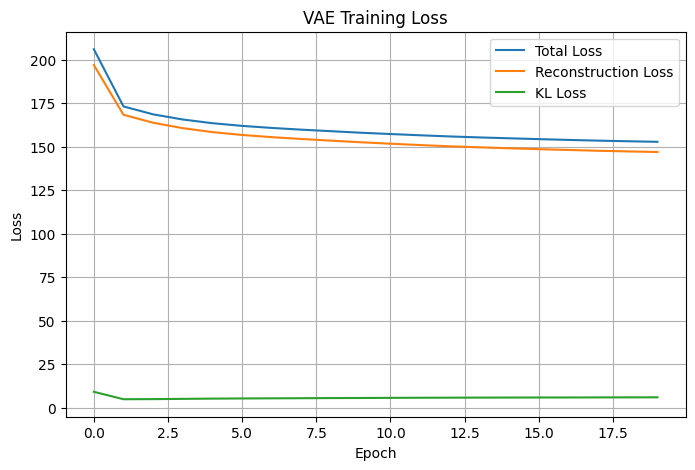

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Total Loss")
plt.plot(
    history.history["reconstruction_loss"],
    label="Reconstruction Loss"
)
plt.plot(history.history["kl_loss"], label="KL Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss")
plt.legend()
plt.grid()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


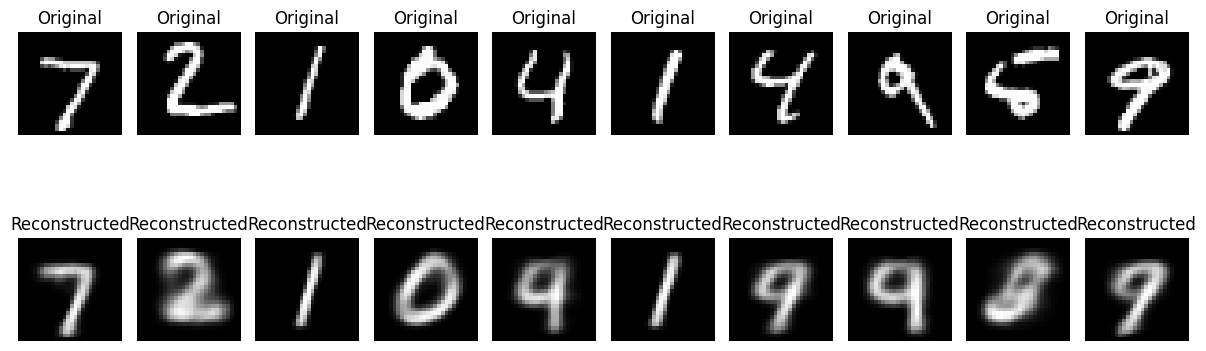

In [ ]:
# Select 10 test images
original_images = x_test[:10]

# Encode
z_mean_values, z_log_var_values = encoder.predict(
    original_images
)

# Sample
z_values = Sampling()(
    [z_mean_values, z_log_var_values]
)

# Decode
reconstructed_images = decoder.predict(z_values)

plt.figure(figsize=(12, 5))

for i in range(10):

    # Original
    plt.subplot(2, 10, i + 1)
    plt.imshow(
        original_images[i].reshape(28, 28),
        cmap="gray"
    )
    plt.axis("off")
    plt.title("Original")

    # Reconstructed
    plt.subplot(2, 10, i + 11)
    plt.imshow(
        reconstructed_images[i].reshape(28, 28),
        cmap="gray"
    )
    plt.axis("off")
    plt.title("Reconstructed")

plt.tight_layout()
plt.show()

Why do reconstructed digits sometimes look slightly blurred?

Answer: The VAE optimizes probabilistic reconstruction and regularization. Its generated outputs can average over multiple plausible handwriting styles.


 Generate completely new handwritten digits


Until now, we have reconstructed images that were already given to the model.

Now we will generate new images without providing any original input image.

We sample random values from the standard normal distribution.

Then pass them through the decoder.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


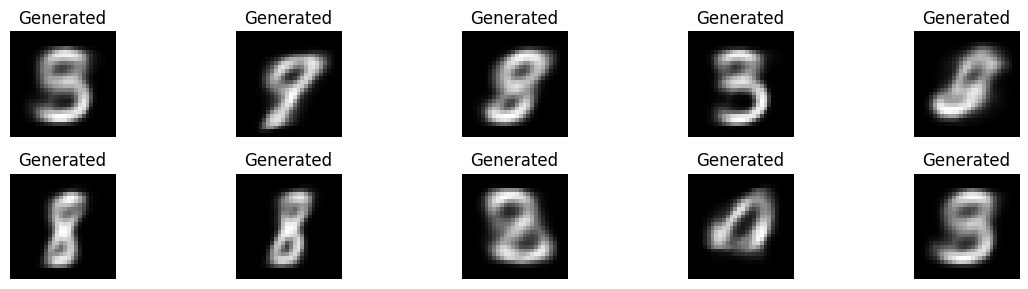

In [ ]:
# Generate 10 random latent vectors
random_latent_vectors = np.random.normal(
    size=(10, latent_dim)
).astype("float32")

# Generate new images
generated_images = decoder.predict(
    random_latent_vectors
)

plt.figure(figsize=(12, 3))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        generated_images[i].reshape(28, 28),
        cmap="gray"
    )

    plt.title("Generated")
    plt.axis("off")

plt.tight_layout()
plt.show()

These are synthetic images generated from random latent vectors. They are not simply copies of the training images.

This demonstrates the generative capability of a VAE.

Visualize the latent space
Remember that we selected latent_dim = 2.

This means each handwritten digit is represented by two latent coordinates.

Let's visualize how different digits are distributed in this two-dimensional space.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


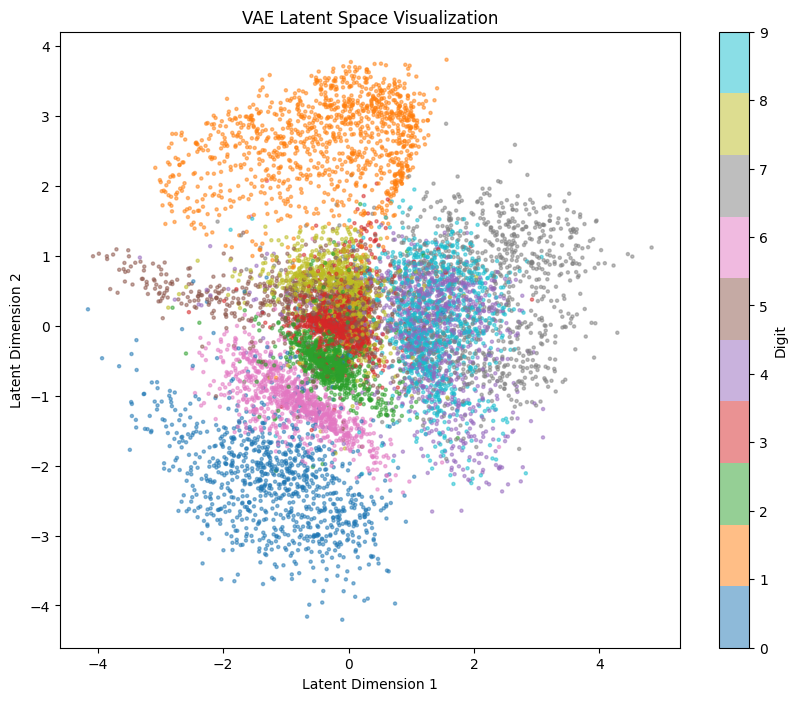

In [ ]:
# Encode test dataset
z_mean_values, _ = encoder.predict(x_test)

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    z_mean_values[:, 0],
    z_mean_values[:, 1],
    c=y_test,
    cmap="tab10",
    alpha=0.5,
    s=5
)

plt.colorbar(scatter, label="Digit")
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("VAE Latent Space Visualization")

plt.show()

Generate images using latent space interpolation
This is an excellent demonstration of why a continuous latent space is useful.

Suppose we have two latent vectors:
- Point A: [-2, -2]
- Point B: [2, 2]
We gradually move from A to B and generate images at intermediate positions.

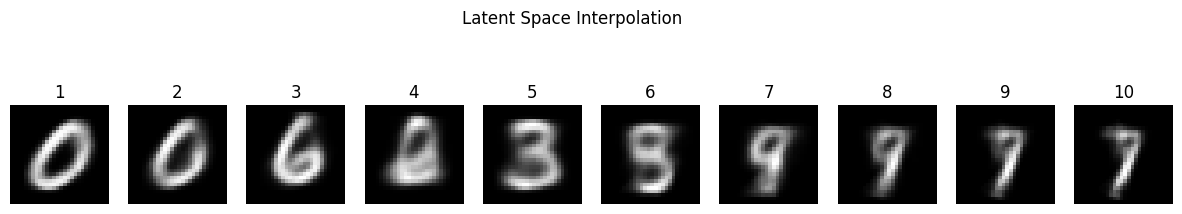

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

point_a = np.array([-2.0, -2.0])
point_b = np.array([2.0, 2.0])

steps = 10

interpolated_images = []

for alpha in np.linspace(0, 1, steps):

    z = (1 - alpha) * point_a + alpha * point_b

    z = z.reshape(1, 2)

    generated = decoder.predict(z, verbose=0)

    interpolated_images.append(
        generated[0].reshape(28, 28)
    )

plt.figure(figsize=(15, 3))

for i, img in enumerate(interpolated_images):

    plt.subplot(1, steps, i + 1)
    plt.imshow(img, cmap="gray")
    plt.axis("off")
    plt.title(f"{i+1}")

plt.suptitle("Latent Space Interpolation")

plt.show()

What does this demonstrate?

The decoder generates images as we move through the latent space.

Instead of jumping randomly between unrelated representations, we can explore intermediate latent points and observe how the generated images change.

The transition may not always be visually smooth or meaningful, but it demonstrates the principle of latent space interpolation.